# GhostJob: exploratory analysis (Phase 3)

This notebook looks at the first snapshot of postings from ~200 company job boards. It covers:

1. **Data quality.** Is the data complete and trustworthy?
2. **How long postings stay open.** The distribution of days open, by industry and by ATS.
3. **Reposting.** How often one requisition is posted again, by industry and by company.
4. **Salary transparency.** Who shows pay, and where.
5. **Survival curve.** How long postings take to close (Kaplan-Meier, lifelines).

The findings are summarized in plain English in [`docs/FINDINGS.md`](../docs/FINDINGS.md). Charts are saved to
`docs/figures/`.

**How to run:** `make eda` (or `uv run jupyter nbconvert --execute --inplace analytics/01_eda.ipynb`). It reads
from `DATABASE_URL` (the local Docker DB by default). Every "today" number uses the date of the latest successful
pipeline run, so the results can be reproduced from the same data.

In [1]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from lifelines import KaplanMeierFitter
from matplotlib.ticker import PercentFormatter

REPO = Path.cwd().parent if Path.cwd().name == "analytics" else Path.cwd()
sys.path.insert(0, str(REPO / "pipelines"))
from ghostjob_pipelines.db import connect  # noqa: E402
from ghostjob_pipelines.load import decode_payload  # noqa: E402

FIG_DIR = REPO / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140)
conn = connect()


def sql(query: str, params: tuple = ()) -> pd.DataFrame:
    cur = conn.execute(query, params)
    return pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])


AS_OF = sql(
    "SELECT max(run_date) AS d FROM pipeline_runs WHERE status IN ('success', 'partial')"
).d[0]
print("as of", AS_OF)

as of 2026-11-21


### Chart style

The colors come from a palette that has been checked for colorblind safety. Some of its colors are low-contrast
on the light background, so every chart labels its values directly instead of relying on color alone.

In [2]:
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"  # categorical slots 1-2

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "text.color": INK,
        "axes.labelcolor": INK_2,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.edgecolor": AXIS,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "lines.linewidth": 2,
        "figure.dpi": 110,
        "savefig.dpi": 160,
        "savefig.bbox": "tight",
    }
)


def hbar(ax, labels, values, fmt="{:.0%}", color=BLUE):
    """Horizontal bars, largest on top, value printed at the end of each bar."""
    y = range(len(labels))[::-1]
    ax.barh(list(y), values, color=color, height=0.62, edgecolor=SURFACE, linewidth=2)
    ax.set_yticks(list(y), labels, color=INK_2)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    top = max(values)
    for yi, v in zip(y, values, strict=True):
        ax.text(v + top * 0.01, yi, fmt.format(v), va="center", color=INK, fontsize=9)
    ax.set_xlim(0, top * 1.15)
    if "%" in fmt:
        ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## 1. Data quality

Questions: how many runs and boards do we have, did any boards fail, which fields are missing, and can we trust
the dates the ATS gives us?

In [3]:
runs = sql(
    "SELECT id, run_date, trigger, status, companies_total, companies_failed, postings_seen, postings_new,"
    " postings_closed, quality_notes FROM pipeline_runs ORDER BY id"
)
print(
    f"{len(runs)} pipeline runs over {runs.run_date.nunique()} day(s); snapshot days:",
    sql("SELECT count(DISTINCT snapshot_date) AS n FROM posting_snapshots").n[0],
)
runs

3 pipeline runs over 1 day(s); snapshot days: 1


,id,run_date,trigger,status,companies_total,companies_failed,postings_seen,postings_new,postings_closed,quality_notes
0,1,2026-11-21,cron,success,208,0,27412,27412,0,None
1,2,2026-11-21,cron,success,208,0,27412,1,1,None
2,3,2026-11-21,cron,success,208,0,27413,7,6,None


In [4]:
fetches = sql("""
    SELECT f.status, count(*) AS n FROM company_fetches f
    WHERE f.run_id = (SELECT max(id) FROM pipeline_runs WHERE status IN ('success', 'partial'))
    GROUP BY 1""")
fetches

,status,n
0,ok,208


In [5]:
postings = sql("""
    SELECT p.id, p.company_id, co.name AS company, co.ats, co.industry, p.source_job_id, p.title,
           p.title_normalized, p.location, p.remote_type, p.seniority, p.employment_type, p.department,
           p.salary_min, p.salary_max, p.salary_currency, p.salary_source,
           p.source_created_at, p.source_updated_at, p.first_seen_at, p.closed_at, p.is_active, t.word_count
    FROM postings p JOIN companies co ON co.id = p.company_id
    LEFT JOIN posting_text t ON t.posting_id = p.id""")
for col in ["source_created_at", "source_updated_at", "first_seen_at", "closed_at"]:
    postings[col] = pd.to_datetime(postings[col], utc=True)
for col in ["salary_min", "salary_max", "word_count"]:
    postings[col] = pd.to_numeric(postings[col])
postings["age_days"] = (
    pd.Timestamp(AS_OF) - postings.source_created_at.dt.tz_localize(None).dt.normalize()
).dt.days
active = postings[postings.is_active].copy()
print(
    f"{len(postings):,} postings, {len(active):,} active, {postings.company_id.nunique()} companies"
)
missing = postings[
    [
        "location",
        "remote_type",
        "department",
        "employment_type",
        "salary_min",
        "source_created_at",
        "source_updated_at",
        "word_count",
    ]
]
missing = (
    missing.replace({"": None, "unknown": None}).isna().mean().rename("share missing").to_frame()
)
missing.style.format("{:.1%}")

27,420 postings, 27,413 active, 208 companies


,share missing
location,0.0%
remote_type,62.7%
department,0.1%
employment_type,73.5%
salary_min,40.1%
source_created_at,0.0%
source_updated_at,26.6%
word_count,0.0%


In [6]:
dupes = postings.duplicated(["company_id", "source_job_id"]).sum()
neg_age = (postings.age_days < 0).sum()
major = postings.salary_currency.isin(["USD", "CAD", "EUR", "GBP", "AUD", "SGD", "CHF", "NZD"])
bad_salary = (
    (postings.salary_min > postings.salary_max) | (major & (postings.salary_max > 2_000_000))
).sum()
short = (postings.word_count < 50).sum()
print(f"duplicate (company, job id) rows: {dupes}")
print(f"postings created after the snapshot date: {neg_age}")
print(f"impossible salaries (min > max, or over 2M in a major currency): {bad_salary}")
print(
    "  (amounts over 2M in INR, KRW, HUF, etc. are normal; sanitize_salary now drops major-currency ones)"
)
print(f"descriptions under 50 words: {short} ({short / len(postings):.1%})")

duplicate (company, job id) rows: 0
postings created after the snapshot date: 0
impossible salaries (min > max, or over 2M in a major currency): 1
  (amounts over 2M in INR, KRW, HUF, etc. are normal; sanitize_salary now drops major-currency ones)
descriptions under 50 words: 2 (0.0%)


### Can we trust the ATS dates?

**Posting dates (`source_created_at`).** Every ATS gives a "created" or "published" date, but they don't mean
the same thing. The table below shows that Lever postings look far older than Greenhouse or Ashby postings.
Lever's `createdAt` is when the posting record was created. Companies keep one Lever posting open for years
("evergreen" roles), while on Greenhouse a re-published role usually gets a new `first_published` date.
**This means posting age must be compared within an ATS, not across them.**

In [7]:
by_ats = active.groupby("ats").age_days.agg(
    postings="size",
    median_days="median",
    share_60d=lambda s: (s >= 60).mean(),
    share_1y=lambda s: (s >= 365).mean(),
)
by_ats.style.format({"median_days": "{:.0f}", "share_60d": "{:.0%}", "share_1y": "{:.0%}"})

,postings,median_days,share_60d,share_1y
ats,,,,
ashby,4214,46,42%,4%
greenhouse,20125,54,47%,6%
lever,3074,236,78%,42%


**"Last updated" dates (`source_updated_at`, Greenhouse only).** Some companies bulk-touch every posting at once,
which resets `updated_at` without anyone editing the job. When most of a company's postings share one
`updated_at` day, that date says nothing about the individual job.

In [8]:
gh = active[(active.ats == "greenhouse") & active.source_updated_at.notna()].copy()
gh["upd_day"] = gh.source_updated_at.dt.date
per_co = gh.groupby("company").upd_day.agg(
    n="size", top_day_share=lambda s: s.value_counts(normalize=True).iloc[0]
)
per_co = per_co[per_co.n >= 20]
bulk = (per_co.top_day_share >= 0.8).mean()
print(
    f"{bulk:.0%} of Greenhouse companies (with 20+ postings) have 80%+ of postings sharing one updated_at day"
)
per_co.sort_values("top_day_share", ascending=False).head(8)

19% of Greenhouse companies (with 20+ postings) have 80%+ of postings sharing one updated_at day


,n,top_day_share
company,,
Akuna Capital,33,1.000000
Intercom,120,1.000000
Braze,344,0.994186
IMC Trading,151,0.993377
Natera,204,0.990196
Scale AI,169,0.976331
Navan,237,0.974684
Stripe,778,0.969152


**Data-quality takeaways**
- No duplicate keys, impossible dates or impossible salaries. These are also enforced by the dbt tests.
- **Posting age is ATS-specific.** Lever ages run years longer. Any age feature in the Phase 6 model must be
  relative to the ATS, or must use our own `first_seen_at` once we have enough history.
- **`updated_at` is unreliable for bulk-touch companies.** A posting "refreshed" on the same day as all the others
  isn't a real refresh. Phase 6 should only count a refresh when it's specific to that posting.
- We have only a few snapshot days so far. Anything that needs closures (time to close, the survival curve) is
  preliminary and gets more accurate with every daily run.

## 2. How long do postings stay open?

Days open = snapshot date minus the ATS creation date. Because of the Lever issue above, the headline numbers use
**Greenhouse + Ashby only**. Lever is shown separately.

Greenhouse + Ashby: 24,339 active postings; median 53 days open; 46% open 60+ days; 15% open 180+ days


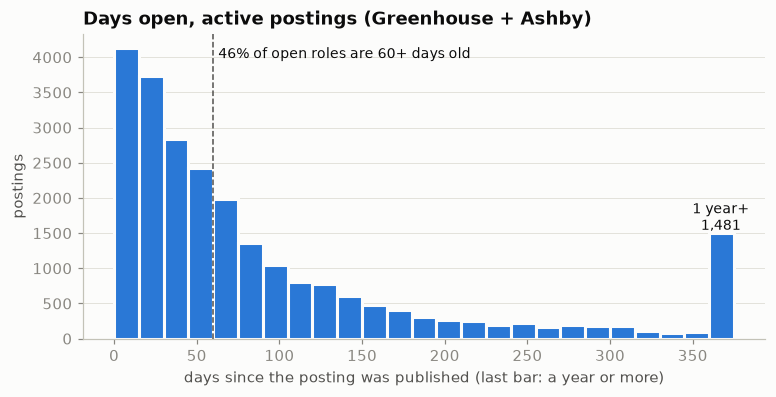

In [9]:
ga = active[active.ats != "lever"]
print(
    f"Greenhouse + Ashby: {len(ga):,} active postings; median {ga.age_days.median():.0f} days open; "
    f"{(ga.age_days >= 60).mean():.0%} open 60+ days; {(ga.age_days >= 180).mean():.0%} open 180+ days"
)

fig, ax = plt.subplots(figsize=(8, 3.6))
clipped = ga.age_days.clip(upper=365)
ax.hist(clipped, bins=range(0, 380, 15), color=BLUE, edgecolor=SURFACE, linewidth=2)
ax.axvline(60, color=INK_2, linewidth=1, linestyle="--")
ax.text(
    63,
    ax.get_ylim()[1] * 0.92,
    f"{(ga.age_days >= 60).mean():.0%} of open roles are 60+ days old",
    color=INK,
    fontsize=9,
)
ax.set_title("Days open, active postings (Greenhouse + Ashby)")
ax.text(
    367,
    (ga.age_days >= 365).sum(),
    f"1 year+\n{(ga.age_days >= 365).sum():,}",
    ha="center",
    va="bottom",
    fontsize=9,
)
ax.set_xlabel("days since the posting was published (last bar: a year or more)")
ax.set_ylabel("postings")
ax.grid(axis="x", visible=False)
save(fig, "days_open_distribution")

,all ATS,Greenhouse + Ashby,Lever share of postings
industry,,,
consulting,66,66,1%
finance,57,54,0%
tech,53,52,5%
healthcare,82,51,47%
retail,85,48,29%


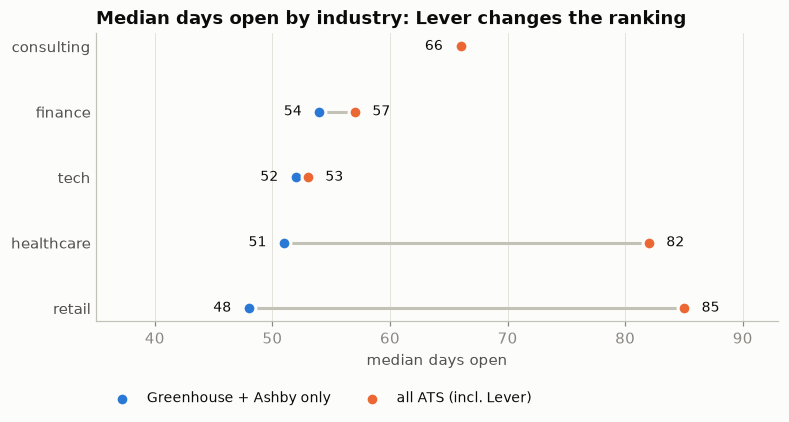

In [10]:
ind = pd.DataFrame(
    {
        "all ATS": active.groupby("industry").age_days.median(),
        "Greenhouse + Ashby": ga.groupby("industry").age_days.median(),
    }
).sort_values("Greenhouse + Ashby", ascending=False)
ind["Lever share of postings"] = active.assign(l=active.ats == "lever").groupby("industry").l.mean()
display(
    ind.style.format(
        {"all ATS": "{:.0f}", "Greenhouse + Ashby": "{:.0f}", "Lever share of postings": "{:.0%}"}
    )
)

fig, ax = plt.subplots(figsize=(8, 3.4))
y = range(len(ind))[::-1]
for yi, (_, r) in zip(y, ind.iterrows(), strict=True):
    ax.plot([r["Greenhouse + Ashby"], r["all ATS"]], [yi, yi], color=AXIS, linewidth=2, zorder=1)
ax.scatter(
    ind["Greenhouse + Ashby"],
    list(y),
    color=BLUE,
    s=70,
    zorder=2,
    edgecolor=SURFACE,
    linewidth=2,
    label="Greenhouse + Ashby only",
)
ax.scatter(
    ind["all ATS"],
    list(y),
    color=ORANGE,
    s=70,
    zorder=2,
    edgecolor=SURFACE,
    linewidth=2,
    label="all ATS (incl. Lever)",
)
for yi, (_, r) in zip(y, ind.iterrows(), strict=True):
    lo, hi = sorted([r["Greenhouse + Ashby"], r["all ATS"]])
    ax.text(lo - 1.5, yi, f"{lo:.0f}", ha="right", va="center", fontsize=9)
    if hi - lo >= 1:
        ax.text(hi + 1.5, yi, f"{hi:.0f}", ha="left", va="center", fontsize=9)
ax.set_yticks(list(y), ind.index, color=INK_2)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlim(35, ind.values[:, :2].max() + 8)
ax.set_xlabel("median days open")
ax.set_title("Median days open by industry: Lever changes the ranking")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.2), ncol=2, frameon=False, fontsize=9)
save(fig, "days_open_by_industry")

### Year-old postings are concentrated in a few companies

2,768 active postings are a year or more old (10% of active); the top 10 companies hold 64% of them


,postings,ats,share_1y,median_days,year_old
company,,,,,
Gopuff,755,lever,89%,1249,669
Veeva,860,lever,33%,187,287
Palantir,308,lever,60%,513,186
Databricks,896,greenhouse,19%,93,170
Anduril,2631,greenhouse,6%,64,167
DoorDash,409,greenhouse,16%,67,65
Verkada,352,greenhouse,16%,88,58
Point72,202,greenhouse,28%,119,56
Datadog,382,greenhouse,14%,86,54


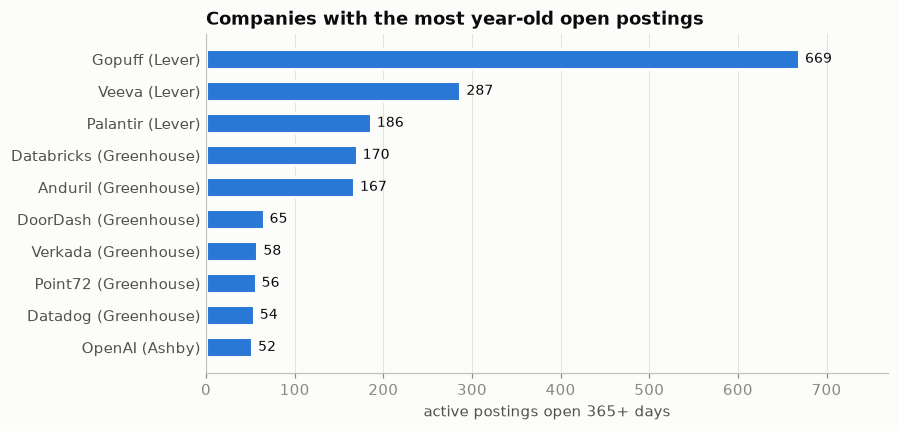

In [11]:
old = active[active.age_days >= 365]
top_old = old.company.value_counts().head(10)
print(
    f"{len(old):,} active postings are a year or more old ({len(old) / len(active):.0%} of active); "
    f"the top 10 companies hold {top_old.sum() / len(old):.0%} of them"
)
co_age = active.groupby("company").agg(
    postings=("id", "size"),
    ats=("ats", "first"),
    share_1y=("age_days", lambda s: (s >= 365).mean()),
    median_days=("age_days", "median"),
)
top_tbl = co_age.loc[top_old.index].assign(year_old=top_old)
display(top_tbl.style.format({"share_1y": "{:.0%}", "median_days": "{:.0f}"}))

fig, ax = plt.subplots(figsize=(8, 4))
hbar(
    ax,
    [f"{c} ({top_tbl.ats[c].title()})" for c in top_old.index],
    top_old.values.tolist(),
    fmt="{:,.0f}",
)
ax.set_title("Companies with the most year-old open postings")
ax.set_xlabel("active postings open 365+ days")
save(fig, "year_old_by_company")

## 3. Reposting

Reposting means the same job is posted again as a new listing. Detecting it fully needs history (a posting
closes, and a near-identical one appears later) and text embeddings, which is Phase 4.

Greenhouse already exposes a direct signal. Every post carries an `internal_job_id`: the **requisition** it
belongs to. One requisition can have several live posts. When those posts were published **more than 30 days
apart**, the company has re-published the same requisition. That's a repost we can see today, without waiting for
history. Posts of one requisition published on the same day are usually multi-city copies, not reposts.

In [12]:
rows = conn.execute("""
    SELECT DISTINCT ON (r.company_id, r.source_job_id) r.company_id, r.source_job_id, r.payload_gz
    FROM raw_jobs r JOIN companies co ON co.id = r.company_id
    JOIN postings p ON p.company_id = r.company_id AND p.source_job_id = r.source_job_id AND p.is_active
    WHERE co.ats = 'greenhouse'
    ORDER BY r.company_id, r.source_job_id, r.fetched_at DESC""").fetchall()
req = []
for company_id, sid, blob in rows:
    p = decode_payload(blob)
    req.append((company_id, sid, p.get("internal_job_id"), p.get("first_published")))
req = pd.DataFrame(req, columns=["company_id", "source_job_id", "requisition", "first_published"])
req["first_published"] = pd.to_datetime(req.first_published, utc=True, errors="coerce")
req = req.dropna(subset=["requisition"]).merge(
    active[["company_id", "company", "industry"]].drop_duplicates(), on="company_id"
)

reqs = (
    req.groupby(["company", "industry", "requisition"])
    .agg(
        posts=("source_job_id", "size"),
        span_days=("first_published", lambda s: (s.max() - s.min()).days),
    )
    .reset_index()
)
reqs["multi_post"] = reqs.posts > 1
reqs["republished"] = reqs.multi_post & (reqs.span_days > 30)
print(f"{len(reqs):,} Greenhouse requisitions with {reqs.posts.sum():,} live posts")
print(
    f"{reqs.multi_post.mean():.1%} have more than one live post; "
    f"{reqs.republished.mean():.1%} were re-published (posts 30+ days apart)"
)
print(
    f"of the multi-post requisitions, {reqs[reqs.multi_post].republished.mean():.0%} are re-publications"
)

16,435 Greenhouse requisitions with 20,055 live posts
12.0% have more than one live post; 4.3% were re-published (posts 30+ days apart)
of the multi-post requisitions, 35% are re-publications


,requisitions,multi_post,republished
industry,,,
tech,9825,13.8%,5.2%
healthcare,1001,10.4%,4.0%
consulting,1139,8.7%,3.8%
finance,2930,10.0%,2.7%
retail,1540,7.9%,1.8%


,requisitions,republished,republished_n
company,,,
Third Bridge,85,17.6%,15
Nuro,78,15.4%,12
Anduril,1560,14.9%,232
Brex,77,14.3%,11
Samsara,193,14.0%,27
Compass,97,12.4%,12
Hudson River Trading,70,11.4%,8
Intercom,82,11.0%,9
PagerDuty,31,9.7%,3


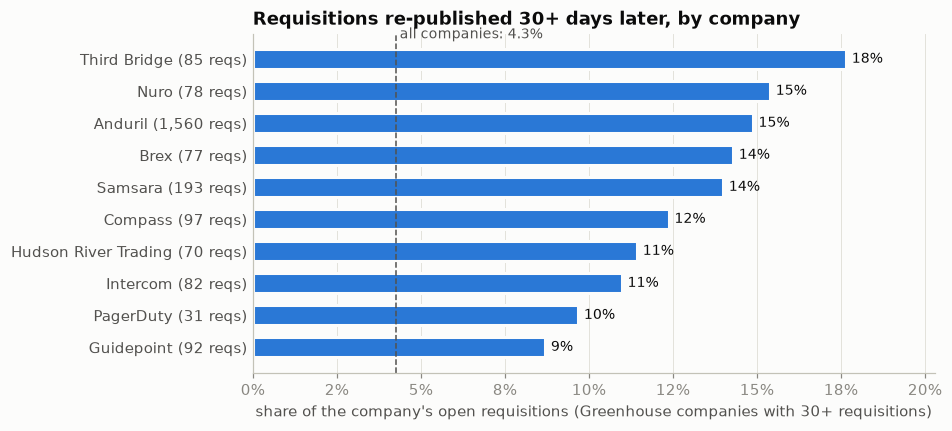

In [13]:
by_ind = (
    reqs.groupby("industry")
    .agg(
        requisitions=("posts", "size"),
        multi_post=("multi_post", "mean"),
        republished=("republished", "mean"),
    )
    .sort_values("republished", ascending=False)
)
display(by_ind.style.format({"multi_post": "{:.1%}", "republished": "{:.1%}"}))

by_co = reqs.groupby("company").agg(
    requisitions=("posts", "size"),
    republished=("republished", "mean"),
    republished_n=("republished", "sum"),
)
by_co = by_co[by_co.requisitions >= 30].sort_values("republished", ascending=False)
display(by_co.head(10).style.format({"republished": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 4))
t = by_co.head(10)
hbar(
    ax,
    [f"{c} ({n:,} reqs)" for c, n in zip(t.index, t.requisitions, strict=True)],
    t.republished.tolist(),
    fmt="{:.0%}",
)
ax.axvline(reqs.republished.mean(), color=INK_2, linewidth=1, linestyle="--")
ax.text(
    reqs.republished.mean(),
    len(t) - 0.35,
    f" all companies: {reqs.republished.mean():.1%}",
    color=INK_2,
    fontsize=9,
)
ax.set_title("Requisitions re-published 30+ days later, by company")
ax.set_xlabel(
    "share of the company's open requisitions (Greenhouse companies with 30+ requisitions)"
)
save(fig, "republished_by_company")

In [14]:
# The biggest examples, to sanity-check the definition by eye.
reqs.sort_values(["republished", "posts"], ascending=False).head(8)

,company,industry,requisition,posts,span_days,multi_post,republished
713,Anduril,tech,4.545213e+09,14,203,True,True
3011,Brex,finance,6.368422e+09,14,157,True,True
1190,Anduril,tech,4.655816e+09,12,79,True,True
14478,Toast,finance,3.141507e+06,12,162,True,True
611,Anduril,tech,4.407695e+09,11,50,True,True
760,Anduril,tech,4.576898e+09,11,250,True,True
1147,Anduril,tech,4.650779e+09,11,72,True,True
2202,Anthropic,tech,4.445618e+09,10,209,True,True


In [15]:
reopened = postings.groupby("industry").apply(
    lambda d: (d.closed_at.notna()).sum(), include_groups=False
)
print("closures observed so far, by industry:", reopened.to_dict())
print(
    "times a closed posting re-opened:",
    int(sql("SELECT coalesce(sum(times_reopened), 0) AS n FROM postings").n[0]),
)

closures observed so far, by industry: {'consulting': 0, 'finance': 2, 'healthcare': 0, 'retail': 1, 'tech': 4}


times a closed posting re-opened: 0


## 4. Salary transparency

A posting "shows salary" if the ATS gives a structured range or the description has a USD range that we can parse
(see `clean.py`). Locations are grouped by whether the US state has a **pay-transparency law** that covers job
postings: CA, CO, WA, NY, IL, MN, HI, MD, MA, NJ, VT and DC. The grouping is a simple text match on the location
string. A posting listing several states counts as pay-law if any of them has a law.

,postings,shows_salary
loc_group,,
"US, state not given (mostly remote)",4795,91%
"US, pay-law state",10599,82%
"US, no pay law",1762,55%
outside US / unclear,10257,24%


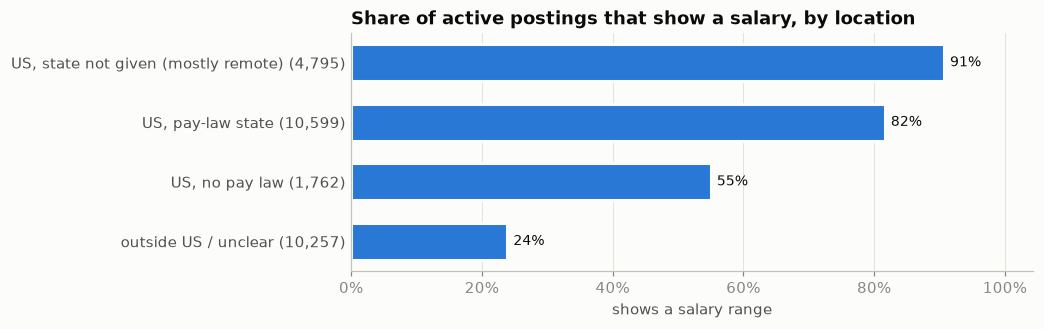

In [16]:
PAY_LAW = {"CA", "CO", "WA", "NY", "IL", "MN", "HI", "MD", "MA", "NJ", "VT", "DC"}
US_STATES = PAY_LAW | set(
    [
        "AL",
        "AK",
        "AZ",
        "AR",
        "CT",
        "DE",
        "FL",
        "GA",
        "ID",
        "IN",
        "IA",
        "KS",
        "KY",
        "LA",
        "ME",
        "MI",
        "MS",
        "MO",
        "MT",
        "NE",
        "NV",
        "NH",
        "NM",
        "NC",
        "ND",
        "OH",
        "OK",
        "OR",
        "PA",
        "RI",
        "SC",
        "SD",
        "TN",
        "TX",
        "UT",
        "VA",
        "WV",
        "WI",
        "WY",
    ]
)  # noqa: SIM905
CITY_STATE = {
    "san francisco": "CA",
    "los angeles": "CA",
    "palo alto": "CA",
    "san jose": "CA",
    "mountain view": "CA",
    "san diego": "CA",
    "new york": "NY",
    "nyc": "NY",
    "seattle": "WA",
    "denver": "CO",
    "chicago": "IL",
    "boston": "MA",
    "washington, dc": "DC",
    "minneapolis": "MN",
    "austin": "TX",
    "dallas": "TX",
    "houston": "TX",
    "atlanta": "GA",
    "miami": "FL",
    "phoenix": "AZ",
    "nashville": "TN",
    "salt lake city": "UT",
    "pittsburgh": "PA",
    "philadelphia": "PA",
    "portland": "OR",
}


def location_group(loc: str | None) -> str:
    loc = loc or ""
    states = set(re.findall(r"\b([A-Z]{2})\b", loc)) & US_STATES
    states |= {st for city, st in CITY_STATE.items() if city in loc.lower()}
    if not states:
        if re.search(r"\b(united states|usa|u\.s\.|us)\b", loc, re.I):
            return "US, state not given (mostly remote)"
        return "outside US / unclear"
    return "US, pay-law state" if states & PAY_LAW else "US, no pay law"


active["has_salary"] = active.salary_min.notna() | active.salary_max.notna()
active["loc_group"] = active.location.map(location_group)
sal = (
    active.groupby("loc_group")
    .has_salary.agg(postings="size", shows_salary="mean")
    .sort_values("shows_salary", ascending=False)
)
display(sal.style.format({"shows_salary": "{:.0%}"}))

fig, ax = plt.subplots(figsize=(8, 2.8))
hbar(
    ax,
    [f"{g} ({n:,})" for g, n in zip(sal.index, sal.postings, strict=True)],
    sal.shows_salary.tolist(),
)
ax.set_title("Share of active postings that show a salary, by location")
ax.set_xlabel("shows a salary range")
save(fig, "salary_by_location")

In [17]:
us = active[active.loc_group.str.startswith("US")]
tbl = pd.DataFrame(
    {
        "by industry (US postings)": us.groupby("industry").has_salary.mean(),
    }
).sort_values("by industry (US postings)")
display(tbl.style.format("{:.0%}"))
display(
    us.groupby("seniority")
    .has_salary.agg(postings="size", shows_salary="mean")
    .sort_values("shows_salary")
    .style.format({"shows_salary": "{:.0%}"})
)
print(
    "salary source:",
    active.salary_source.fillna("none").value_counts(normalize=True).round(3).to_dict(),
)

,by industry (US postings)
industry,
retail,56%
consulting,57%
finance,72%
healthcare,79%
tech,90%


,postings,shows_salary
seniority,,
entry,1072,46%
intern,417,51%
mid,6571,80%
director,757,85%
executive,345,86%
manager,2074,88%
senior,3972,89%
staff_plus,1948,90%


salary source: {'structured': 0.466, 'none': 0.401, 'text': 0.134}


## 5. Survival curve: how long until a posting closes?

Kaplan-Meier estimate of the share of postings still open after *t* days. Two details matter:

- **Censoring.** Postings still open on the snapshot date haven't closed *yet*. They count as censored, not
  as closed.
- **Late entry (left truncation).** We only started watching on our first snapshot. A posting that was already
  200 days old when we first saw it can only tell us about days 200 and later. `entry` = its age when first seen.
  Without this, the curve would be biased toward long-lived postings.

Lever is excluded because of its date issue. **This is preliminary:** with only a few days of history there are
almost no observed closures, so the curve is nearly flat. It becomes meaningful after about 30 daily runs.

24,345 postings, 7 observed closures


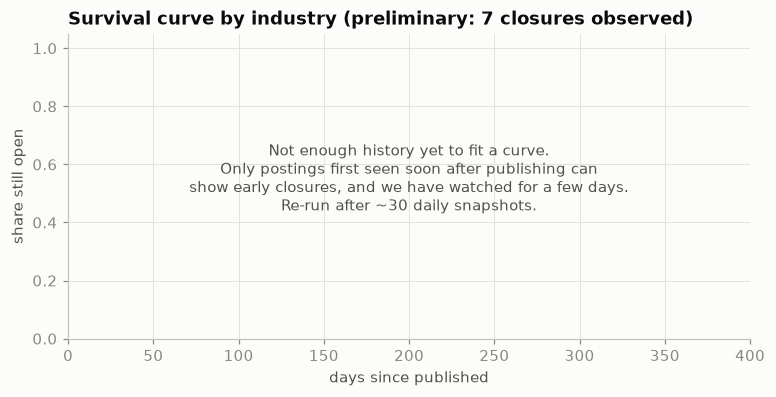

not enough history yet to fit: tech (4 closures), finance (2 closures), retail (1 closures), healthcare (0 closures), consulting (0 closures)


In [18]:
sv = postings[postings.ats != "lever"].dropna(subset=["source_created_at"]).copy()
created = sv.source_created_at.dt.tz_convert("UTC")
end = sv.closed_at.dt.tz_convert("UTC").fillna(pd.Timestamp(AS_OF, tz="UTC") + pd.Timedelta(days=1))
sv["duration"] = ((end - created).dt.total_seconds() / 86400).clip(lower=0.5)
sv["entry"] = ((sv.first_seen_at.dt.tz_convert("UTC") - created).dt.total_seconds() / 86400).clip(
    lower=0
)
sv["entry"] = sv[["entry", "duration"]].min(axis=1) - 1e-6
sv["closed"] = sv.closed_at.notna()
print(f"{len(sv):,} postings, {sv.closed.sum()} observed closures")

from lifelines.exceptions import StatError  # noqa: E402

kmf = KaplanMeierFitter()
fig, ax = plt.subplots(figsize=(8, 3.6))
skipped = []
for i, (name, d) in enumerate(sorted(sv.groupby("industry"), key=lambda x: -len(x[1]))):
    try:
        kmf.fit(d.duration, event_observed=d.closed, entry=d.entry, label=name)
    except StatError:
        # Too few postings at risk early on (we only see young postings for a few days so far).
        skipped.append(f"{name} ({int(d.closed.sum())} closures)")
        continue
    color = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"][i]
    kmf.plot_survival_function(ax=ax, ci_show=False, color=color, linewidth=2)
    last = kmf.survival_function_.iloc[:, 0]
    last = last[last.index <= 365]
    ax.text(365, last.iloc[-1], f" {name}", color=INK_2, fontsize=9, va="center")
ax.set_xlim(0, 400)
ax.set_ylim(0, 1.05)
ax.set_xlabel("days since published")
ax.set_ylabel("share still open")
ax.set_title(f"Survival curve by industry (preliminary: {sv.closed.sum()} closures observed)")
if skipped and len(skipped) == sv.industry.nunique():
    ax.text(
        200,
        0.55,
        "Not enough history yet to fit a curve.\nOnly postings first seen soon after publishing can\n"
        "show early closures, and we have watched for a few days.\nRe-run after ~30 daily snapshots.",
        ha="center",
        va="center",
        color=INK_2,
        fontsize=10,
    )
else:
    ax.legend(frameon=False, fontsize=9, loc="lower left")
save(fig, "survival_preliminary")
if skipped:
    print("not enough history yet to fit:", ", ".join(skipped))

## Numbers used in FINDINGS.md

Written to `docs/figures/findings_numbers.json`, so the write-up can be checked against the notebook.

In [19]:
numbers = {
    "as_of": str(AS_OF),
    "active_postings": int(len(active)),
    "companies": int(active.company_id.nunique()),
    "lever_share_1y": round(float(by_ats.loc["lever", "share_1y"]), 3),
    "greenhouse_share_1y": round(float(by_ats.loc["greenhouse", "share_1y"]), 3),
    "ashby_share_1y": round(float(by_ats.loc["ashby", "share_1y"]), 3),
    "industry_median_days": ind[["all ATS", "Greenhouse + Ashby"]].round(1).to_dict(),
    "ga_median_days": float(ga.age_days.median()),
    "ga_share_60d": round(float((ga.age_days >= 60).mean()), 3),
    "ga_share_180d": round(float((ga.age_days >= 180).mean()), 3),
    "year_old_postings": int(len(old)),
    "year_old_top10_share": round(float(top_old.sum() / len(old)), 3),
    "year_old_top10": top_old.to_dict(),
    "gh_requisitions": int(len(reqs)),
    "gh_multi_post_share": round(float(reqs.multi_post.mean()), 3),
    "gh_republished_share": round(float(reqs.republished.mean()), 3),
    "republished_top_companies": by_co.head(5).republished.round(3).to_dict(),
    "salary_by_location": sal.shows_salary.round(3).to_dict(),
    "bulk_touch_company_share": round(float(bulk), 3),
    "observed_closures": int(sv.closed.sum()),
}
(FIG_DIR / "findings_numbers.json").write_text(json.dumps(numbers, indent=2, default=str) + "\n")
numbers

{'as_of': '2026-11-21',
 'active_postings': 27413,
 'companies': 208,
 'lever_share_1y': 0.419,
 'greenhouse_share_1y': 0.065,
 'ashby_share_1y': 0.042,
 'industry_median_days': {'all ATS': {'consulting': 66.0,
   'finance': 57.0,
   'tech': 53.0,
   'healthcare': 82.0,
   'retail': 85.0},
  'Greenhouse + Ashby': {'consulting': 66.0,
   'finance': 54.0,
   'tech': 52.0,
   'healthcare': 51.0,
   'retail': 48.0}},
 'ga_median_days': 53.0,
 'ga_share_60d': 0.461,
 'ga_share_180d': 0.154,
 'year_old_postings': 2768,
 'year_old_top10_share': 0.637,
 'year_old_top10': {'Gopuff': 669,
  'Veeva': 287,
  'Palantir': 186,
  'Databricks': 170,
  'Anduril': 167,
  'DoorDash': 65,
  'Verkada': 58,
  'Point72': 56,
  'Datadog': 54,
  'OpenAI': 52},
 'gh_requisitions': 16435,
 'gh_multi_post_share': 0.12,
 'gh_republished_share': 0.043,
 'republished_top_companies': {'Third Bridge': 0.176,
  'Nuro': 0.154,
  'Anduril': 0.149,
  'Brex': 0.143,
  'Samsara': 0.14},
 'salary_by_location': {'US, state no